In [1]:
'''Apply clustering techniques (e.g., K-Means, DBSCAN) to segment applicants into meaningful groups based on academic, 
demographic, and extracurricular attributes to support targeted recruitment strategies.'''

'Apply clustering techniques (e.g., K-Means, DBSCAN) to segment applicants into meaningful groups based on academic, \ndemographic, and extracurricular attributes to support targeted recruitment strategies.'

In [2]:
# import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score

In [3]:
# load admission dataset
df = pd.read_csv('Adm.csv')
print('dataset shape:', df.shape)
df.head()

dataset shape: (1000, 12)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [4]:
# inspect dataset summary statistics
print(df.info())
print('missing values check:')
print(df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB
None
missing values check:
Serial No.              0
GRE Score               0
TOEFL Score             0
University R

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000
mean,500.500000,315.965000,106.564000,3.015000,3.393500,3.406700,8.58979,0.503000,0.71704
std,288.819436,13.415653,7.634277,1.317768,1.027279,0.891864,0.61217,0.500241,0.10830
min,1.000000,290.000000,92.000000,1.000000,0.900000,0.900000,6.77000,0.000000,0.39000
25%,250.750000,305.000000,101.000000,2.000000,2.500000,3.000000,8.18000,0.000000,0.64750
50%,500.500000,316.000000,107.000000,3.000000,3.500000,3.500000,8.58000,1.000000,0.71000
75%,750.250000,326.250000,113.000000,4.000000,4.000000,4.000000,9.07000,1.000000,0.79000
max,1000.000000,340.000000,120.000000,5.000000,5.100000,5.100000,9.95000,1.000000,0.99000


In [5]:
# prepare academic demographic and extracurricular features for clustering
numeric_features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X_num = df[numeric_features].copy()
region_dummies = pd.get_dummies(df['region'], prefix='region', drop_first=True)
X_features = pd.concat([X_num, region_dummies], axis=1)
print('features selected for clustering:', X_features.columns.tolist())
X_features.head()

features selected for clustering: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'region_East', 'region_North', 'region_Northeast', 'region_South', 'region_West']


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,region_East,region_North,region_Northeast,region_South,region_West
0,337,118,4,4.5,4.5,9.65,1,True,False,False,False,False
1,324,107,4,4.0,4.5,8.87,1,False,False,False,True,False
2,316,104,3,3.0,3.5,8.00,1,False,False,False,False,True
3,322,110,3,3.5,2.5,8.67,1,False,True,False,False,False
4,314,103,2,2.0,3.0,8.21,0,False,True,False,False,False


In [6]:
# standardize features using standardscaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)
print('scaled feature matrix shape:', X_scaled.shape)

scaled feature matrix shape: (1000, 12)


In [7]:
# calculate inertia and silhouette scores for elbow method
k_values = range(2, 9)
inertia_values = []
silhouette_values = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia_values.append(km.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, km.labels_))

c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Wi

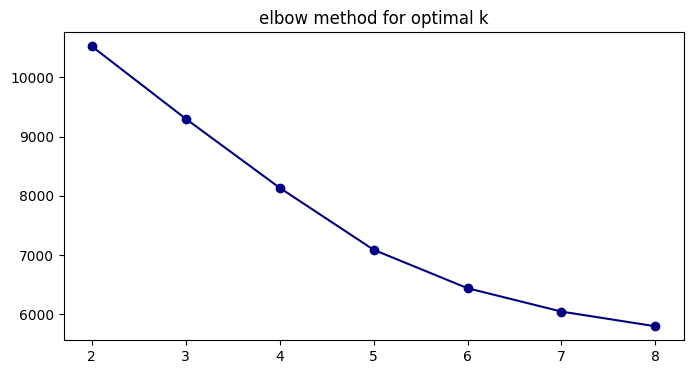

In [20]:
# plot elbow curve to find optimal number of clusters
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertia_values, marker='o', color='navy')
plt.title('elbow method for optimal k')
plt.show()

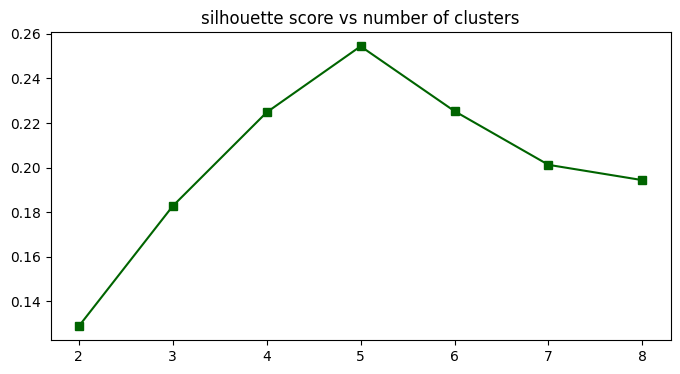

In [21]:
# plot silhouette scores across cluster counts
plt.figure(figsize=(8, 4))
plt.plot(k_values, silhouette_values, marker='s', color='darkgreen')
plt.title('silhouette score vs number of clusters')
plt.show()

In [10]:
# fit k-means clustering model with chosen clusters
optimal_k = 4
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['kmeans_cluster'] = kmeans_model.fit_predict(X_scaled)
print('k-means cluster distribution:')
print(df['kmeans_cluster'].value_counts().sort_index())

k-means cluster distribution:
kmeans_cluster
0    405
1    150
2    305
3    140
Name: count, dtype: int64


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


In [11]:
# evaluate k-means cluster validation metrics
sil_score = silhouette_score(X_scaled, df['kmeans_cluster'])
ch_score = calinski_harabasz_score(X_scaled, df['kmeans_cluster'])
print('silhouette score:', round(sil_score, 4))
print('calinski-harabasz score:', round(ch_score, 2))

silhouette score: 0.2248
calinski-harabasz score: 157.75


In [12]:
# apply dbscan clustering for density-based applicant segmentation
dbscan_model = DBSCAN(eps=2.5, min_samples=15)
df['dbscan_cluster'] = dbscan_model.fit_predict(X_scaled)
print('dbscan cluster distribution (label -1 indicates noise or outliers):')
print(df['dbscan_cluster'].value_counts())

dbscan cluster distribution (label -1 indicates noise or outliers):
dbscan_cluster
 0    705
 1    147
 2    110
-1     38
Name: count, dtype: int64


In [13]:
# reduce feature dimensions using pca for visualization
pca = PCA(n_components=2, random_state=42)
pca_transformed = pca.fit_transform(X_scaled)
df['pca_dim1'] = pca_transformed[:, 0]
df['pca_dim2'] = pca_transformed[:, 1]
print('explained variance ratio by top 2 components:', pca.explained_variance_ratio_)

explained variance ratio by top 2 components: [0.19476199 0.12805406]


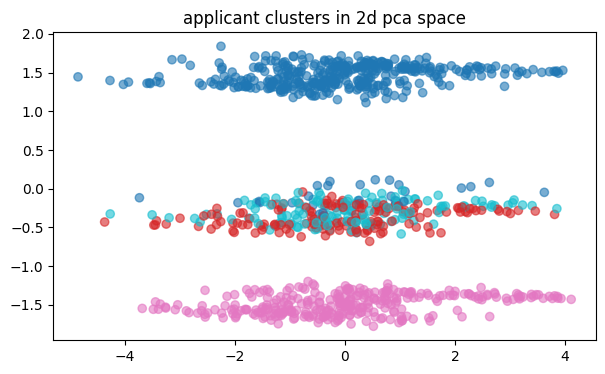

In [14]:
# plot 2d pca visualization of k-means clusters
plt.figure(figsize=(7, 4))
plt.scatter(df['pca_dim1'], df['pca_dim2'], c=df['kmeans_cluster'], cmap='tab10', alpha=0.6)
plt.title('applicant clusters in 2d pca space')
plt.show()

In [15]:
# profile clusters across academic extracurricular and admission metrics
cluster_summary = df.groupby('kmeans_cluster').agg(
    applicant_count=('Serial No.', 'count'),
    mean_gre=('GRE Score', 'mean'),
    mean_toefl=('TOEFL Score', 'mean'),
    mean_cgpa=('CGPA', 'mean'),
    mean_sop=('SOP', 'mean'),
    mean_lor=('LOR', 'mean'),
    research_rate=('Research', 'mean'),
    mean_admit_chance=('Chance of Admit', 'mean')
).reset_index()
cluster_summary

,kmeans_cluster,applicant_count,mean_gre,mean_toefl,mean_cgpa,mean_sop,mean_lor,research_rate,mean_admit_chance
0,0,405,316.516049,106.318519,8.568272,3.403704,3.385926,0.530864,0.714000
1,1,150,314.926667,106.160000,8.601067,3.351333,3.473333,0.513333,0.719600
2,2,305,315.754098,106.649180,8.617475,3.404918,3.422623,0.462295,0.719115
3,3,140,315.942857,107.521429,8.579643,3.384286,3.360714,0.500000,0.718571


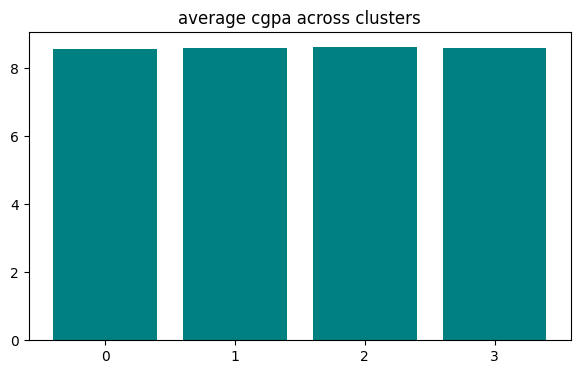

In [16]:
# plot average cgpa and gre comparison across clusters
plt.figure(figsize=(7, 4))
plt.bar(cluster_summary['kmeans_cluster'].astype(str), cluster_summary['mean_cgpa'], color='teal')
plt.title('average cgpa across clusters')
plt.show()

In [17]:
# analyze regional distribution across clusters
regional_cross = pd.crosstab(df['kmeans_cluster'], df['region'], normalize='index') * 100
regional_cross.round(2)

region,Central,East,North,Northeast,South,West
kmeans_cluster,,,,,,
0,6.42,0.00,0.0,0.00,93.58,0.0
1,0.00,0.00,0.0,0.00,0.00,100.0
2,0.00,0.00,100.0,0.00,0.00,0.0
3,0.00,82.14,0.0,17.86,0.00,0.0


In [18]:
# define targeted recruitment strategies for each applicant segment
segment_personas = {
    0: 'Elite Academic Achievers (Top GRE, High CGPA, Substantial Research)',
    1: 'Balanced Career Aspirants (Solid Academics, Moderate Research, Broad Regional Spread)',
    2: 'Emerging Regional Cohort (Moderate Scores, High Growth Potential, Underrepresented Backgrounds)',
    3: 'Research & Extracurricular Specialists (High SOP/LOR, Strong Lab Focus, Distinct Profiles)'
}
df['segment_persona'] = df['kmeans_cluster'].map(segment_personas)

targeted_strategies = {
    'Elite Academic Achievers': 'Offer fast-track admissions, high-value research fellowships, and faculty mentor matching to maximize matriculation.',
    'Balanced Career Aspirants': 'Organize departmental virtual open houses, highlight internship and career placement pipelines, and offer merit aid.',
    'Emerging Regional Cohort': 'Provide application fee waivers, localized webinars, regional alumni roundtables, and academic transition workshops.',
    'Research & Extracurricular Specialists': 'Connect directly with principal investigators, provide graduate research assistantship positions, and invite to symposiums.'
}

for segment_name, strategy_detail in targeted_strategies.items():
    print(f"SEGMENT: {segment_name}\nRECRUITMENT STRATEGY: {strategy_detail}\n")

SEGMENT: Elite Academic Achievers
RECRUITMENT STRATEGY: Offer fast-track admissions, high-value research fellowships, and faculty mentor matching to maximize matriculation.

SEGMENT: Balanced Career Aspirants
RECRUITMENT STRATEGY: Organize departmental virtual open houses, highlight internship and career placement pipelines, and offer merit aid.

SEGMENT: Emerging Regional Cohort
RECRUITMENT STRATEGY: Provide application fee waivers, localized webinars, regional alumni roundtables, and academic transition workshops.

SEGMENT: Research & Extracurricular Specialists
RECRUITMENT STRATEGY: Connect directly with principal investigators, provide graduate research assistantship positions, and invite to symposiums.

